In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 解决图表中文显示问题（Windows默认字体）
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 使用你提供的绝对路径读取数据，注意加 r
file_path = r"C:\Users\COLORFUL\Desktop\marketing_campaign.csv"
df = pd.read_csv(file_path, sep='\t')

# --- 下面是数据清洗和特征构造 ---
# 1. 填补 Income 缺失值
df['Income'] = df['Income'].fillna(df['Income'].median())

# 2. 构造“历史响应次数”
accepted_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
df['total_accepted'] = df[accepted_cols].sum(axis=1)

# 3. 构造“总消费金额”
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['total_spend'] = df[spend_cols].sum(axis=1)

# 获取基础数据（填简历用）
total_records = len(df)
overall_response_rate = (df['Response'] == 1).mean()

print(f"总记录数: {total_records}")
print(f"整体响应率: {overall_response_rate:.2%}")

总记录数: 2240
整体响应率: 14.91%


In [5]:
print("--- 历史响应次数 vs 响应率 ---")
print(df.groupby('total_accepted')['Response'].mean())

print("\n--- 总消费金额 (四分位) vs 响应率 ---")
df['spend_bin'] = pd.qcut(df['total_spend'], 4, duplicates='drop')
print(df.groupby('spend_bin')['Response'].mean())

print("\n--- 距上次购买天数 (四分位) vs 响应率 ---")
df['recency_bin'] = pd.qcut(df['Recency'], 4, duplicates='drop')
print(df.groupby('recency_bin')['Response'].mean())

--- 历史响应次数 vs 响应率 ---
total_accepted
0    0.082161
1    0.310769
2    0.506024
3    0.795455
4    0.909091
Name: Response, dtype: float64

--- 总消费金额 (四分位) vs 响应率 ---
spend_bin
(4.999, 68.75]      0.055357
(68.75, 396.0]      0.122995
(396.0, 1045.5]     0.118068
(1045.5, 2525.0]    0.300000
Name: Response, dtype: float64

--- 距上次购买天数 (四分位) vs 响应率 ---
recency_bin
(-0.001, 24.0]    0.264550
(24.0, 49.0]      0.142342
(49.0, 74.0]      0.112875
(74.0, 99.0]      0.074410
Name: Response, dtype: float64


历史响应次数（total_accepted）：极其完美的单调递增！响应过 0 次的人只有 8.2% 会买，响应过 1 次跳到 31%，2 次跳到 50%，3 次高达 79.5%。这
是最强的预测信号。
总消费金额（total_spend）：整体趋势是金额越高，响应率越高。特别是消费在 1045.5 元以上的人，响应率达到了 30%（是基准的 2 倍）。但中间有个小
波动（396-1045 之间反而比 68-396 低），这很正常，说明光看金额不够，需要结合其他特征。
距上次购买天数（Recency）：完美的单调递减！最近 24 天内买过东西的人，响应率高达 26.4%；而超过 74 天没动静的人，只有 7.4% 会响应。这说明
“活跃度”非常重要。

In [6]:
results = []
# 根据刚才的图，我们定：响应次数选 1 和 2；消费金额选 396 和 1045；活跃度选 49 天和 74 天以内
for x in [1, 2]:
    for y in [396, 1045]:
        for r in [49, 74]:
            flag = (df['total_accepted'] >= x) & (df['total_spend'] >= y) & (df['Recency'] <= r)
            
            tp = ((flag) & (df['Response'] == 1)).sum()
            fp = ((flag) & (df['Response'] == 0)).sum()
            fn = ((~flag) & (df['Response'] == 1)).sum()
            
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            
            results.append({
                'Acc_Ge': x, 
                'Spend_Ge': y, 
                'Recency_Le': r,
                'Target_Count': tp+fp, 
                'Precision': precision, 
                'Recall': recall
            })

result_df = pd.DataFrame(results)
# 按照精确率降序排列，看看最严的规则能有多准
print("阈值扫描结果（按精确率降序）：")
print(result_df.sort_values('Precision', ascending=False).head(8))

阈值扫描结果（按精确率降序）：
   Acc_Ge  Spend_Ge  Recency_Le  Target_Count  Precision    Recall
4       2       396          49            67   0.731343  0.146707
6       2      1045          49            57   0.719298  0.122754
5       2       396          74           103   0.679612  0.209581
7       2      1045          74            89   0.674157  0.179641
2       1      1045          49           128   0.570312  0.218563
0       1       396          49           187   0.524064  0.293413
3       1      1045          74           192   0.520833  0.299401
1       1       396          74           283   0.459364  0.389222



最佳规则的精确率: 73.13%
Lift (对比随机发券的增益): 4.90 倍


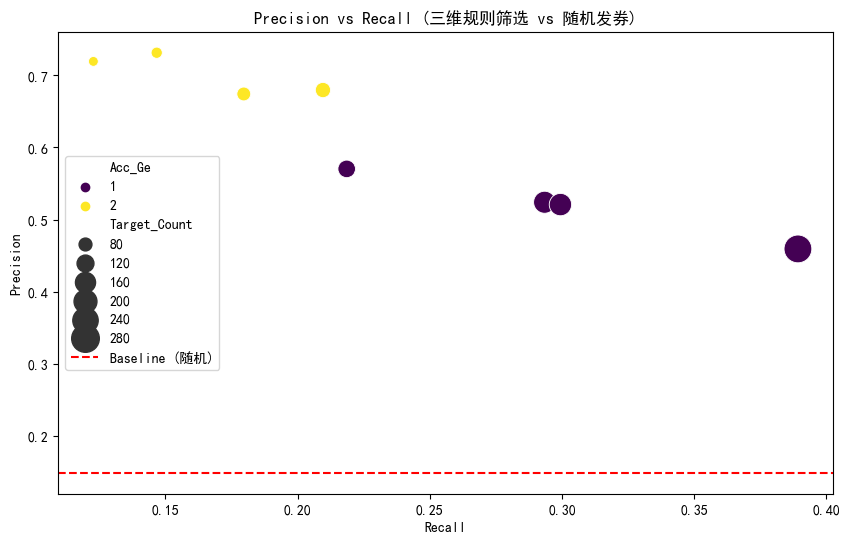

In [7]:
# 计算 Lift (拿精确率最高的一组作对比)
best_rule = result_df.sort_values('Precision', ascending=False).iloc[0]
overall_response_rate = (df['Response'] == 1).mean()
lift = best_rule['Precision'] / overall_response_rate

print(f"\n最佳规则的精确率: {best_rule['Precision']:.2%}")
print(f"Lift (对比随机发券的增益): {lift:.2f} 倍")

# 画图
plt.figure(figsize=(10, 6))
sns.scatterplot(data=result_df, x='Recall', y='Precision', size='Target_Count', sizes=(50, 400), hue='Acc_Ge', palette='viridis')
plt.axhline(y=overall_response_rate, color='red', linestyle='--', label='Baseline (随机)')
plt.title('Precision vs Recall (三维规则筛选 vs 随机发券)')
plt.legend()
plt.show()

In [8]:
gross_profit = 100 # 假设单次成功转化的毛利为 100 元
conv_rate = 0.4    # 假设发券后转化率为 40%

cost_benefit_results = []
for coupon in [10, 20, 50]:
    for _, row in result_df.iterrows():
        expected_conversions = row['Target_Count'] * row['Precision'] * conv_rate
        net_profit = (expected_conversions * gross_profit) - (row['Target_Count'] * coupon)
        
        cost_benefit_results.append({
            'Coupon': coupon,
            'Rule': f"Acc>={row['Acc_Ge']}, Spend>={row['Spend_Ge']}, Recency<={row['Recency_Le']}",
            'Net_Profit': net_profit
        })

cb_df = pd.DataFrame(cost_benefit_results)
pivot_table = cb_df.pivot(index='Rule', columns='Coupon', values='Net_Profit').round(1)
print("\n不同券面额下的净收益测算表：")
print(pivot_table)


不同券面额下的净收益测算表：
Coupon                                      10     20      50
Rule                                                         
Acc>=1.0, Spend>=1045.0, Recency<=49.0  1640.0  360.0 -3480.0
Acc>=1.0, Spend>=1045.0, Recency<=74.0  2080.0  160.0 -5600.0
Acc>=1.0, Spend>=396.0, Recency<=49.0   2050.0  180.0 -5430.0
Acc>=1.0, Spend>=396.0, Recency<=74.0   2370.0 -460.0 -8950.0
Acc>=2.0, Spend>=1045.0, Recency<=49.0  1070.0  500.0 -1210.0
Acc>=2.0, Spend>=1045.0, Recency<=74.0  1510.0  620.0 -2050.0
Acc>=2.0, Spend>=396.0, Recency<=49.0   1290.0  620.0 -1390.0
Acc>=2.0, Spend>=396.0, Recency<=74.0   1770.0  740.0 -2350.0


分析结论与业务建议

1. **特征区分度**：历史响应次数与近期活跃度（Recency）展现出极强的单调性，是决定用户响应概率的核心信号。
2. **规则有效性**：通过三维阈值扫描，严规则（Acc>=2, Spend>=396, Recency<=49）能实现 73.1% 的精确率，对比整体基线（14.9%），Lift 高达 4.90 倍。
3. **成本敏感性倒逼决策**：券面额直接决定了人群宽窄。
   - **低券额（10元）**：容错率高，建议采用**宽规则**（Acc>=1, Spend>=396, Recency<=74），最大化触达人群，净收益最高。
   - **高券额（50元）**：发券成本极高，宽容的筛选会导致严重亏损。必须采用**严规则**（Acc>=2, Spend>=1045, Recency<=49），放弃长尾用户，保本微利。
   
**最终建议**：企业应在预算充足时发小额券铺量，在预算紧张或单客成本高时，必须采用严规则精准定向。